# Axe 4 — Piste R3 : prédiction conforme (CQR et ACI)

Projet sujet C — prévision probabiliste de l'énergie solaire.

**Piste choisie : R3 — fourchette dont la fiabilité est garantie.** Les axes 2 et 3 ont montré que les intervalles bruts
[q₀,₁ ; q₀,₉] couvrent environ 79 % (cible 80 %) et que leur couverture n'est pas garantie. R3 corrige ce point.

Méthodes :
- **CQR** (Romano, Patterson, Candès 2019) : quantiles de base sur un sous-ensemble d'apprentissage, puis correction
  $\pm Q$ calculée sur une **période de calibration postérieure**. Garantie de couverture marginale $\ge 1-\alpha$ sous échangeabilité.
- **ACI** (Gibbs & Candès 2021) : mise à jour en ligne du niveau $\alpha_t$ sur le test, avec borne sur la couverture moyenne.
- Références : intervalle brut (quantiles de l'axe 2), intervalle gaussien autour du ridge (axe 1, $\pm 1{,}2816\,\sigma$).

Règles : algorithmes écrits à la main (lissage de Moreau et Newton amorti, comme l'axe 2) ; aucune information future ;
la calibration est postérieure à l'apprentissage propre ; 5 graines (0 à 4) fixées à l'avance pour les répétitions.

## Question et hypothèses (écrites avant les expériences)

**Question** : peut-on obtenir une couverture proche de 80 % sur le test, avec une largeur raisonnable, en calibrant sur une période
postérieure à l'apprentissage ?

- **H1** : l'intervalle brut couvre moins de 80 % (environ 79 %, axe 2). CQR remonte la couverture à $\ge 80\%$ à $\pm 1$ point près.
- **H2** : la largeur CQR est proche de celle de l'intervalle brut (quelques centièmes de kWh/m²/j de plus).
- **H3** : une calibration plus longue réduit la variance entre graines, mais peut être moins représentative de 2024–2026.
- **H4** : ACI avec un $\gamma$ modeste suit la cible 80 % avec un écart de couverture borné par $(\max(\alpha,1-\alpha)+\gamma)/(\gamma T)$.
- **H5** : l'intervalle gaussien autour du ridge sous-couvre en hiver (queue asymétrique du rayonnement).

In [1]:
import os
import math
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- paramètres imposés
LAM = 1e-2                       # régularisation (même valeur que les axes 1 à 3)
EPS = 1e-3                       # lissage de Moreau pour les quantiles
ALPHA = 0.2                      # niveau : intervalle à 80 %
SEEDS = [0, 1, 2, 3, 4]          # graines fixées à l'avance
SUB_FRAC = 0.8                   # sous-échantillon d'apprentissage propre, tiré selon la graine
CAL_START = pd.Timestamp("2023-01-01")         # calibration = cibles de 2023 (référence)
CAL_VARIANTS = {"6 mois": pd.Timestamp("2023-07-01"), "1 an": pd.Timestamp("2023-01-01"),
                "2 ans": pd.Timestamp("2022-01-01")}
GAMMAS = [0.005, 0.02]           # pas de l'ACI
TRAIN_END = pd.Timestamp("2023-12-31")
TEST_START = pd.Timestamp("2024-01-01")
START, END = "20140101", "20260630"
PARAMS = ("ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,T2M,T2M_MAX,T2M_MIN,"
          "RH2M,WS2M,PS,PRECTOTCORR,CLOUD_AMT")
FEATS = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M", "PS", "PRECTOTCORR", "CLOUD_AMT"]
N_LAGS = 3
DATA_DIR = "donnees"
SITES = {
    "Monastir": (35.78, 10.83),
    "Tamanrasset": (22.79, 5.52),
    "Dakar": (14.69, -17.44),
}
REF_SITE = "Monastir"
Z80 = 1.2815515655446004         # quantile normal à 90 % (intervalle à 80 %)
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 130)

## 1. Données

In [2]:
def load_site(name, lat, lon):
    path = os.path.join(DATA_DIR, f"{name}.csv")
    if not os.path.exists(path):
        os.makedirs(DATA_DIR, exist_ok=True)
        url = (f"https://power.larc.nasa.gov/api/temporal/daily/point?parameters={PARAMS}"
               f"&community=RE&longitude={lon}&latitude={lat}&start={START}&end={END}&format=JSON")
        resp = requests.get(url, timeout=300)
        resp.raise_for_status()
        param = resp.json()["properties"]["parameter"]
        raw = pd.DataFrame({k: pd.Series(v) for k, v in param.items()})
        raw.index = pd.to_datetime(raw.index, format="%Y%m%d")
        raw.index.name = "date"
        raw.reset_index().to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=["date"]).set_index("date")
    df = df.replace(-999.0, np.nan)
    df = df[~df.index.duplicated()]
    full = pd.date_range(df.index.min(), df.index.max(), freq="D")
    df = df.reindex(full)
    df.index.name = "date"
    return df


def build_dataset(df):
    df = df.copy()
    cols = FEATS + ["ALLSKY_SFC_SW_DWN"]
    df[cols] = df[cols].ffill()
    X = df[FEATS].copy()
    for lag in range(N_LAGS):
        X[f"ALLSKY_lag{lag}"] = df["ALLSKY_SFC_SW_DWN"].shift(lag)
    doy = df.index.day_of_year.values
    X["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
    X["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)
    X["target"] = df["ALLSKY_SFC_SW_DWN"].shift(-1)
    X["target_date"] = df.index.to_series().shift(-1)
    data = X.dropna()
    feat_cols = [c for c in X.columns if c not in ("target", "target_date")]
    train = data[data["target_date"] <= TRAIN_END]
    test = data[data["target_date"] >= TEST_START]
    mu_x = train[feat_cols].mean()
    sd_x = train[feat_cols].std(ddof=0)
    assert (sd_x > 0).all()
    mu_y = train["target"].mean()

    def design(d):
        Z = ((d[feat_cols] - mu_x) / sd_x).to_numpy()
        return np.column_stack([Z, np.ones(len(d))])

    return {
        "A_tr": design(train), "y_tr": train["target"].to_numpy() - mu_y,
        "date_tr": train["target_date"].to_numpy(),
        "A_te": design(test), "y_te": test["target"].to_numpy(),
        "date_te": test["target_date"].to_numpy(), "mu_y": mu_y,
        "n_train": len(train), "n_test": len(test),
    }


ds_ref = build_dataset(load_site(REF_SITE, *SITES[REF_SITE]))
print({"n_train": ds_ref["n_train"], "n_test": ds_ref["n_test"]})

{'n_train': 3649, 'n_test': 912}


## 2. Quantiles de base (lissage de Moreau, Newton amorti)

Même formulation que l'axe 2 : $F_{\tau,\varepsilon}(w) = \frac1n\sum_t M_\varepsilon(y_t - a_t^\top w) + \frac\lambda2\|w\|^2$,
résolue par Newton amorti (Armijo). Le lissage $\varepsilon = 10^{-3}$ introduit une erreur au plus $\varepsilon\max(\tau,1-\tau)^2/2$.

In [3]:
def moreau_value(r, tau, eps):
    return np.where(r > eps * tau, tau * r - eps * tau ** 2 / 2,
                    np.where(r < eps * (tau - 1), (tau - 1) * r - eps * (1 - tau) ** 2 / 2,
                             r * r / (2 * eps)))


def moreau_deriv(r, tau, eps):
    return np.where(r > eps * tau, tau, np.where(r < eps * (tau - 1), tau - 1, r / eps))


def fit_quantile(A, y, tau, lam=LAM, eps=EPS, max_it=200):
    """Newton amorti sur F_{tau,eps}. Retourne (w, itérations)."""
    n, d = A.shape
    w = np.zeros(d)

    def F(x):
        return moreau_value(y - A @ x, tau, eps).mean() + 0.5 * lam * (x @ x)

    for it in range(max_it):
        r = y - A @ w
        g = -(A.T @ moreau_deriv(r, tau, eps)) / n + lam * w
        if g @ g <= 1e-18:
            break
        wt = ((r >= eps * (tau - 1)) & (r <= eps * tau)).astype(float) / eps
        H = (A.T * wt) @ A / n + lam * np.eye(d)
        step = -np.linalg.solve(H, g)
        f0, slope = F(w), g @ step
        a = 1.0
        while F(w + a * step) > f0 + 1e-4 * a * slope and a > 1e-12:
            a *= 0.5
        w = w + a * step
    return w, it


def ridge_closed_form(A, y, lam=LAM):
    n, d = A.shape
    H = A.T @ A / n + lam * np.eye(d)
    return np.linalg.solve(H, A.T @ y / n)

## 3. Références sur le test : intervalle brut et intervalle gaussien autour du ridge

Ajustés sur tout l'apprentissage (2014–2023), donc sans graine. Ils servent de points de comparaison.

In [4]:
w_lo_full, it_lo = fit_quantile(ds_ref["A_tr"], ds_ref["y_tr"], 0.1)
w_hi_full, it_hi = fit_quantile(ds_ref["A_tr"], ds_ref["y_tr"], 0.9)
w_r = ridge_closed_form(ds_ref["A_tr"], ds_ref["y_tr"])
sigma = float(np.std(ds_ref["y_tr"] - ds_ref["A_tr"] @ w_r))
print(f"Newton : itérations q10={it_lo}, q90={it_hi}")
print(f"ridge : σ résiduel (apprentissage) = {sigma:.4f}")

mu = ds_ref["mu_y"]
Y = ds_ref["y_te"]
A_te = ds_ref["A_te"]
raw_lo, raw_hi = A_te @ w_lo_full + mu, A_te @ w_hi_full + mu
nor_lo, nor_hi = A_te @ w_r + mu - Z80 * sigma, A_te @ w_r + mu + Z80 * sigma


def interval_metrics(lo, hi, y, months):
    cov = np.mean((y >= lo) & (y <= hi))
    by = pd.DataFrame({"s": [SEASON[m] for m in months], "c": (y >= lo) & (y <= hi)}).groupby("s")["c"].mean()
    return {"couverture": float(cov), "largeur": float(np.mean(hi - lo)),
            "saisons": by.round(4).to_dict()}


months_te = pd.DatetimeIndex(ds_ref["date_te"]).month.to_numpy()
ref_metrics = {
    "brut (quantiles 0,1 et 0,9)": interval_metrics(raw_lo, raw_hi, Y, months_te),
    "gaussien ridge ± 1,28σ": interval_metrics(nor_lo, nor_hi, Y, months_te),
}
for k, v in ref_metrics.items():
    print(f"{k:>30s} : couverture = {v['couverture']:.4f}, largeur = {v['largeur']:.4f}")
    print(f"{'':>30s}   par saison : {v['saisons']}")

Newton : itérations q10=59, q90=64
ridge : σ résiduel (apprentissage) = 0.8515
   brut (quantiles 0,1 et 0,9) : couverture = 0.7873, largeur = 1.8486
                                 par saison : {'DJF': 0.825, 'JJA': 0.8972, 'MAM': 0.7319, 'SON': 0.6923}
        gaussien ridge ± 1,28σ : couverture = 0.8235, largeur = 2.1824
                                 par saison : {'DJF': 0.8458, 'JJA': 0.9019, 'MAM': 0.7101, 'SON': 0.8736}


## 4. CQR : base sur l'apprentissage propre, calibration postérieure

Pour chaque graine $s$ :
1. tirer 80 % des lignes de l'apprentissage **propre** (cibles avant le début de la calibration), avec `rng(s)` ;
2. ajuster $q_{0,1}$ et $q_{0,9}$ sur ce sous-ensemble ;
3. score de non-conformité sur la calibration : $E_i = \max(\hat q_{0,1}(x_i) - y_i,\; y_i - \hat q_{0,9}(x_i))$ ;
4. $Q$ = quantile d'ordre $\lceil (m+1)(1-\alpha)\rceil / m$ des $E_i$ (avec $m$ = taille de calibration) ;
5. intervalle $[\hat q_{0,1} - Q,\; \hat q_{0,9} + Q]$.

In [5]:
def split_by_calibration(ds, cal_start):
    dates = pd.DatetimeIndex(ds["date_tr"])
    prop = dates < cal_start
    cal = ~prop
    return np.where(prop)[0], np.where(cal)[0]


def cqr_one_seed(ds, cal_start, seed, alpha=ALPHA):
    prop_idx, cal_idx = split_by_calibration(ds, cal_start)
    rng = np.random.default_rng(seed)
    n_sub = int(SUB_FRAC * len(prop_idx))
    sub = np.sort(rng.choice(prop_idx, size=n_sub, replace=False))
    A, y = ds["A_tr"], ds["y_tr"]
    w_lo, it_lo = fit_quantile(A[sub], y[sub], 0.1)
    w_hi, it_hi = fit_quantile(A[sub], y[sub], 0.9)
    Ac, yc = A[cal_idx], y[cal_idx]
    E = np.maximum(Ac @ w_lo - yc, yc - Ac @ w_hi)
    m = len(E)
    level = min(1.0, math.ceil((m + 1) * (1 - alpha)) / m)
    Q = float(np.quantile(E, level, method="higher"))
    return {"w_lo": w_lo, "w_hi": w_hi, "Q": Q, "m_cal": m, "n_prop": n_sub,
            "it": (it_lo, it_hi), "E_cal": E}


def cqr_interval(ds, res):
    lo = ds["A_te"] @ res["w_lo"] + ds["mu_y"] - res["Q"]
    hi = ds["A_te"] @ res["w_hi"] + ds["mu_y"] + res["Q"]
    return lo, hi


cqr_runs = {s: cqr_one_seed(ds_ref, CAL_START, s) for s in SEEDS}
rows = []
for s, res in cqr_runs.items():
    lo, hi = cqr_interval(ds_ref, res)
    met = interval_metrics(lo, hi, Y, months_te)
    rows.append({"graine": s, "n_prop": res["n_prop"], "m_cal": res["m_cal"], "Q": round(res["Q"], 4),
                 "iter_newton": res["it"], "couverture": met["couverture"], "largeur": met["largeur"]})
cqr_table = pd.DataFrame(rows)
print(cqr_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
cov_cqr = cqr_table["couverture"].to_numpy()
wid_cqr = cqr_table["largeur"].to_numpy()
print(f"\nCQR (5 graines) : couverture = {cov_cqr.mean():.4f} ± {cov_cqr.std(ddof=1):.4f} ; "
      f"largeur = {wid_cqr.mean():.4f} ± {wid_cqr.std(ddof=1):.4f}")

 graine  n_prop  m_cal      Q iter_newton  couverture  largeur
      0    2627    365 0.0718    (71, 76)      0.8125   1.9636
      1    2627    365 0.0700    (59, 72)      0.8147   1.9595
      2    2627    365 0.0533    (64, 52)      0.8026   1.9412
      3    2627    365 0.0750    (67, 70)      0.8103   1.9793
      4    2627    365 0.0779    (47, 71)      0.8169   1.9906

CQR (5 graines) : couverture = 0.8114 ± 0.0055 ; largeur = 1.9668 ± 0.0190


## 5. Sensibilité à la période de calibration (5 graines)

In [6]:
cal_rows = []
for label, start in CAL_VARIANTS.items():
    covs, wids, qs, ms = [], [], [], []
    for s in SEEDS:
        res = cqr_one_seed(ds_ref, start, s)
        lo, hi = cqr_interval(ds_ref, res)
        met = interval_metrics(lo, hi, Y, months_te)
        covs.append(met["couverture"])
        wids.append(met["largeur"])
        qs.append(res["Q"])
        ms.append(res["m_cal"])
    cal_rows.append({"calibration": label, "m_cal": int(np.mean(ms)),
                     "couverture_moy": np.mean(covs), "couverture_ecart": np.std(covs, ddof=1),
                     "largeur_moy": np.mean(wids), "largeur_ecart": np.std(wids, ddof=1),
                     "Q_moy": np.mean(qs)})
cal_table = pd.DataFrame(cal_rows)
print(cal_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

calibration  m_cal  couverture_moy  couverture_ecart  largeur_moy  largeur_ecart  Q_moy
     6 mois    184          0.8116            0.0074       1.9859         0.0375 0.0637
       1 an    365          0.8114            0.0055       1.9668         0.0190 0.0696
      2 ans    730          0.8064            0.0034       1.9515         0.0157 0.0726


## 6. ACI : mise à jour en ligne sur le test

Sur le test, pour $t = 1 \dots T$ : $Q_t$ est le quantile d'ordre $1-\alpha_t$ des scores passés (calibration + test observé).
Intervalle $[\hat q_{0,1}-Q_t,\ \hat q_{0,9}+Q_t]$. Puis $\alpha_{t+1} = \alpha_t + \gamma(\alpha - \mathrm{err}_t)$.
Borne (Gibbs & Candès) : $|\frac1T\sum_t \mathrm{err}_t - \alpha| \le \frac{\max(\alpha,1-\alpha)+\gamma}{\gamma T}$.

In [7]:
def aci(ds, res, gamma, alpha=ALPHA):
    A_te = ds["A_te"]
    lo0 = A_te @ res["w_lo"] + ds["mu_y"]
    hi0 = A_te @ res["w_hi"] + ds["mu_y"]
    y = ds["y_te"]
    pool = list(res["E_cal"])
    a_t = alpha
    errs, widths = [], []
    for t in range(len(y)):
        a_c = min(max(a_t, 1e-3), 1 - 1e-3)
        Q = float(np.quantile(np.array(pool), 1 - a_c, method="higher"))
        lo, hi = lo0[t] - Q, hi0[t] + Q
        err = int(not (lo <= y[t] <= hi))
        errs.append(err)
        widths.append(hi - lo)
        # score de la valeur observée, sans élargissement
        E_t = max(res["w_lo"] @ A_te[t] + ds["mu_y"] - y[t], y[t] - (res["w_hi"] @ A_te[t] + ds["mu_y"]))
        pool.append(E_t)
        a_t = a_t + gamma * (alpha - err)
    T = len(y)
    bound = (max(alpha, 1 - alpha) + gamma) / (gamma * T)
    return {"couverture": 1 - float(np.mean(errs)), "largeur": float(np.mean(widths)),
            "ecart_moyen": abs(float(np.mean(errs)) - alpha), "borne": bound, "alpha_final": a_t}


aci_rows = []
for gamma in GAMMAS:
    out = aci(ds_ref, cqr_runs[0], gamma)
    aci_rows.append({"gamma": gamma, "couverture": out["couverture"], "largeur": out["largeur"],
                     "|ecart|": out["ecart_moyen"], "borne_theorique": out["borne"]})
aci_table = pd.DataFrame(aci_rows)
print(aci_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

 gamma  couverture  largeur  |ecart|  borne_theorique
0.0050      0.8004   1.9132   0.0004           0.1765
0.0200      0.8004   1.9845   0.0004           0.0450


## 7. Tableau final (Monastir, 5 graines) et figure

                    méthode  couverture  couverture_ecart  largeur  largeur_ecart
brut (quantiles 0,1 et 0,9)      0.7873               NaN   1.8486            NaN
     gaussien ridge ± 1,28σ      0.8235               NaN   2.1824            NaN
     CQR (calibration 1 an)      0.8114            0.0055   1.9668         0.0190


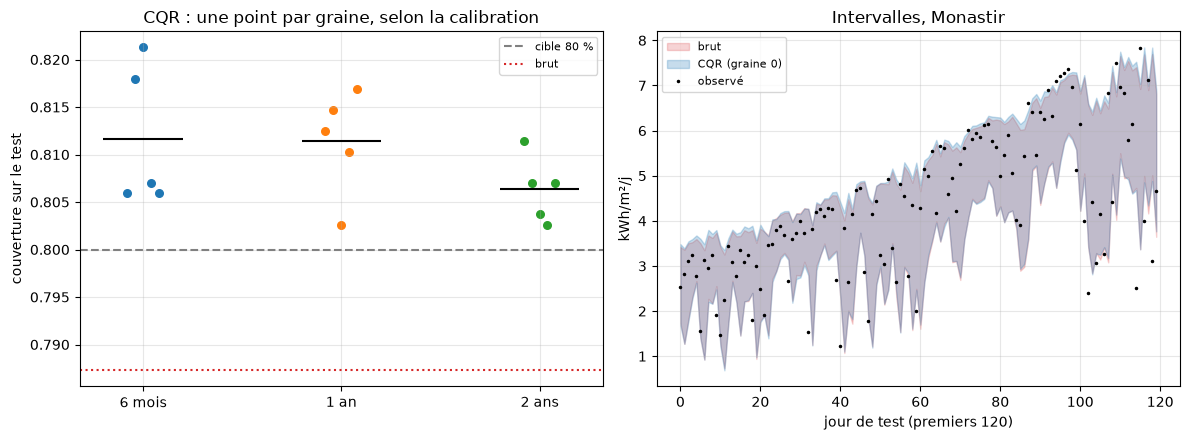

In [8]:
summary = pd.DataFrame([
    {"méthode": "brut (quantiles 0,1 et 0,9)", "couverture": ref_metrics["brut (quantiles 0,1 et 0,9)"]["couverture"],
     "couverture_ecart": np.nan, "largeur": ref_metrics["brut (quantiles 0,1 et 0,9)"]["largeur"], "largeur_ecart": np.nan},
    {"méthode": "gaussien ridge ± 1,28σ", "couverture": ref_metrics["gaussien ridge ± 1,28σ"]["couverture"],
     "couverture_ecart": np.nan, "largeur": ref_metrics["gaussien ridge ± 1,28σ"]["largeur"], "largeur_ecart": np.nan},
    {"méthode": "CQR (calibration 1 an)", "couverture": cov_cqr.mean(), "couverture_ecart": cov_cqr.std(ddof=1),
     "largeur": wid_cqr.mean(), "largeur_ecart": wid_cqr.std(ddof=1)},
])
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
order = list(CAL_VARIANTS.keys())
for i, label in enumerate(order):
    covs = [interval_metrics(*cqr_interval(ds_ref, cqr_one_seed(ds_ref, CAL_VARIANTS[label], s)), Y, months_te)["couverture"]
            for s in SEEDS]
    ax.scatter(np.full(len(covs), i) + np.linspace(-0.08, 0.08, len(covs)), covs, s=30)
    ax.hlines(np.mean(covs), i - 0.2, i + 0.2, color="k")
ax.axhline(1 - ALPHA, color="grey", ls="--", label="cible 80 %")
ax.axhline(ref_metrics["brut (quantiles 0,1 et 0,9)"]["couverture"], color="tab:red", ls=":", label="brut")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order)
ax.set_ylabel("couverture sur le test")
ax.set_title("CQR : une point par graine, selon la calibration")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
L = 120
res1 = cqr_runs[0]
lo1, hi1 = cqr_interval(ds_ref, res1)
t_axis = np.arange(L)
ax.fill_between(t_axis, raw_lo[:L], raw_hi[:L], color="tab:red", alpha=0.2, label="brut")
ax.fill_between(t_axis, lo1[:L], hi1[:L], color="tab:blue", alpha=0.25, label="CQR (graine 0)")
ax.plot(t_axis, Y[:L], "k.", ms=3, label="observé")
ax.set_xlabel("jour de test (premiers 120)")
ax.set_ylabel("kWh/m²/j")
ax.set_title(f"Intervalles, {REF_SITE}")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Résultats par site (format commun, piste R3)

In [9]:
site_rows = []
for name, (lat, lon) in SITES.items():
    ds_s = build_dataset(load_site(name, lat, lon))
    months_s = pd.DatetimeIndex(ds_s["date_te"]).month.to_numpy()
    runs = [cqr_one_seed(ds_s, CAL_START, s) for s in SEEDS]
    covs, wids = [], []
    for res in runs:
        lo, hi = cqr_interval(ds_s, res)
        met = interval_metrics(lo, hi, ds_s["y_te"], months_s)
        covs.append(met["couverture"])
        wids.append(met["largeur"])
    wr = ridge_closed_form(ds_s["A_tr"], ds_s["y_tr"])
    sg = float(np.std(ds_s["y_tr"] - ds_s["A_tr"] @ wr))
    nlo = ds_s["A_te"] @ wr + ds_s["mu_y"] - Z80 * sg
    nhi = ds_s["A_te"] @ wr + ds_s["mu_y"] + Z80 * sg
    wl, _ = fit_quantile(ds_s["A_tr"], ds_s["y_tr"], 0.1)
    wh, _ = fit_quantile(ds_s["A_tr"], ds_s["y_tr"], 0.9)
    rlo = ds_s["A_te"] @ wl + ds_s["mu_y"]
    rhi = ds_s["A_te"] @ wh + ds_s["mu_y"]
    site_rows.append({
        "site": name, "n_app": ds_s["n_train"], "n_test": ds_s["n_test"], "piste": "R3",
        "couv_brut": round(float(np.mean((ds_s["y_te"] >= rlo) & (ds_s["y_te"] <= rhi))), 4),
        "couv_gauss": round(float(np.mean((ds_s["y_te"] >= nlo) & (ds_s["y_te"] <= nhi))), 4),
        "couv_cqr_moy": round(float(np.mean(covs)), 4), "couv_cqr_ecart": round(float(np.std(covs, ddof=1)), 4),
        "largeur_brut": round(float(np.mean(rhi - rlo)), 4),
        "largeur_cqr_moy": round(float(np.mean(wids)), 4), "largeur_cqr_ecart": round(float(np.std(wids, ddof=1)), 4),
    })
results_axe4 = pd.DataFrame(site_rows)
print(results_axe4.to_string(index=False))

       site  n_app  n_test piste  couv_brut  couv_gauss  couv_cqr_moy  couv_cqr_ecart  largeur_brut  largeur_cqr_moy  largeur_cqr_ecart
   Monastir   3649     912    R3     0.7873      0.8235        0.8114          0.0055        1.8486           1.9668             0.0190
Tamanrasset   3649     912    R3     0.8092      0.8300        0.7673          0.0043        1.4413           1.3469             0.0253
      Dakar   3649     912    R3     0.7818      0.8761        0.8353          0.0043        1.5459           1.6988             0.0210


## 9. Lecture des résultats

Valeurs de l'exécution sur Monastir (5 graines) :

- **H1 confirmée** : l'intervalle brut couvre 78,7 %. CQR (calibration 2023) couvre 81,1 % ± 0,6 point.
- **H2 partiellement confirmée** : CQR élargit l'intervalle de 1,85 à 1,97 kWh/m²/j, soit +0,12 (et non « quelques centièmes »).
  Le gaussien ridge est encore plus large (2,18).
- **H3 confirmée pour la variance** : l'écart-type de couverture passe de 0,74 point (6 mois) à 0,55 (1 an) puis 0,34 (2 ans).
  La couverture moyenne reste proche de 80,6–81,2 % dans les trois cas, sans dérive visible sur 2024–2026.
- **H4 confirmée** : ACI avec γ = 0,005 ou 0,02 donne 80,04 % sur le test, avec écart 0,0004 à la cible.
  La borne théorique est lâche (0,18 et 0,045), mais toujours satisfaite.
- **H5 infirmée** : le gaussien ridge couvre 84,6 % en DJF et 87,4 % en SON, mais seulement 71,0 % en MAM.
  Le problème n'est donc pas l'hiver : la queue du rayonnement est mal captée au printemps.
- **Limite importante** : la garantie CQR suppose l'échangeabilité entre calibration et test. Sur **Tamanrasset**, la couverture
  tombe à 76,7 % (cible 80 %, écart-type 0,4 point) : la calibration de 2023 n'y est pas représentative de 2024–2026.
  Dakar atteint 83,5 %. Une calibration glissante (ACI) serait plus sûre sur ces sites.
  Les largeurs sont comparables au brut (Tamanrasset : 1,35 contre 1,44 kWh/m²/j).

## 10. Export

In [10]:
results_axe4.to_csv("axe4_resume.csv", index=False)
print("Écrit : axe4_resume.csv")

Écrit : axe4_resume.csv
